#### 1 & 2)

##### Edge list:
You store the graph as a set of vertices $V$ and a set of edges which are tuple pairs of vertices ($E \subseteq V \times V$). We assume that the sets are stored as linked lists. The space complexity of an edge list representation is $\Theta(|V| + |E|)$, since you need to store each edge and node separately. However, checking whether an edge is present between two nodes $i, j \in V$ is at worst time complexity $\mathcal{O}(|E|)$ since you need to iterate over all edges to find it as it is stored as a linked list and worst case it is the last edge in the set. If the list is kept sorted or a tree index is used, the time complexity can be reduced to $\mathcal{O}(log(|E|))$, but for now we assume we dont use that. Retrieving all neighbors of a certain node $i$ is then again $\mathcal{O}(|E|)$ as you need to go over all edges. Adding an edge can be constant time as you can append it to the end of the linked list, which means it has time complexity $\mathcal{O}(1)$. This does assume that we dont check for duplicates, if we have to check for duplicates the time complexity becomes $\mathcal{O}(|E|)$ again. Removing an edge means finding it and removing it, finding the edge has time complexity $\mathcal{O}(|E|)$ and removing it after finding it is constant. 

##### Adjacency list:
An adjacency list contains of a list of vertices, where each vertex in the list of vertices points towards a list of direct neighbors of that vertex (fig. 1). This has a space complexity of $\Theta(|V| + |E|)$ as you need to store each vertex with its corresponding neighbors, or edges. 

<img src="adjacency_list.jpg" width="40%">

*Figure 1: Graphical representation of an adjacency lists graph representation. Image is from [GeeksforGeeks](https://www.geeksforgeeks.org/dsa/graph-and-its-representations/)*

Finding a specific edge can be done in time complexity $\mathcal{O}(|V|)$ as the first node needs to be found and then the second node. Retrieving all neighbors of a node is again $\mathcal{O}(|V|)$ as you only need to iterate over the vertices until you have found the vertex from which you want to know its neighbors. Adding or removing an edge both have time complexity $\mathcal{O}(|V|)$ since for adding the edge you need to check whether the edge is there or not and then add it if its not, and for removing you need to find the edge as well. 

##### Adjacency matrix:
The adjacency matrix $A$ is a matrix representation for the graph which has the shape $V \times V$. For $i, j \in [0,|V|), \: A[i][j]=1$ if $i$ is connected to $j$ and $A[i][j]=0$ if there is no connection. This has a space complexity of $\Theta(|V|^2)$. 

Retrieving if a edge is present can be achieved in $\mathcal{O}(1)$ time complexity as you can directly check $A[i][j]$. Then retrieving all neighbors of a node is achievable in $|V| \cdot \mathcal{O}(1) = \mathcal{O}(|V|)$ since you need to check for each pair if the edge exists or not. Then removing or adding an edge is again constant time $\mathcal{O}(1)$ since you can simply assign the value 0 or 1 at that index. 

#### 3)

We have to identify which data structure is most suitable for a sparse and dense network. For a dense network there are far more edges than vertices: $|E| \gg |V|$. This means that an edge list data structure is not useful as most of the operations have time complexity $\mathcal{O}(|E|)$. Then a choice has to be made between the adjacency list, and the adjacency matrix. The adjacency matrix memory usage scales harder for really large graphs with many vertices. However, since we are working with a dense graph, the number of edges $|E| \approx |V|^2$. This means that the memory usage of a linked list is even larger. So for a dense graph an adjacency matrix is preferred as it has superior computational time complexity and almost the same memory complexity.  

For a sparse network it becomes less obvious. The adjacency matrix has a large memory complexity there which might not be optimal for really large graphs. The choice then remains between adjacency lists and edge lists. They have the same memory complexity, but an edge list on average has time complexity $\mathcal{O}(|E|)$, while an adjacency list has time complexity $\mathcal{O}(|V|)$. So if $|E| < |V|$ then the edge list, otherwise the adjacency list. 

#### 4)
For one million nodes, the adjacency matrix has $1.000.000^2$ values. Since it only contains 0, or 1, we can store it using $int8$ values. This means that it would require $1.000.000^2 \cdot 8 = 8 \cdot 10^{12}$ bits which is 1000 GB of storage. This is unfeasible so a adjacency list or edge list is required. If the average degree is relatively low, it most likely means that $|E| > |V|$, so then the adjacency list would be the best representation as they have the same memory but less time complexity with operations on the graph as the number of vertices is most likely less then edges.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
def Link_Stub_Reconnection(deg_seq):

  vertices = set(np.arange(len(deg_seq)))
  stubs = []
  for i, deg in enumerate(deg_seq):
    stubs += [i]*deg
  edges = [tuple(edge) for edge in np.random.choice(stubs, (int(len(stubs)//2), 2), replace=False)]

  return edges


### Space Complexity 

Since the algorithm needs to store a list of all vertices and edges, the space complexity become $\Theta(|E| + |V|)$, where $|E|$ and $|V|$ are the cardinality of the edge list $E$ and vertices set $V$ respectively. 

### Time Complexity

The firs step in the algorithm is adding the stubs to a list which has a time complexity of $\mathcal{O}(|E|)$ due to adding $k_{i}$ stubs to the list for vertex $i$. To be more precise the actual time it takes is $2|E|$, however,  $\mathcal{O}(2|E|)=\mathcal{O}(|E|)$. Then we have to pop 2 stubs from the stubs list and add them to the edge list. Picking the pairs of stubs has time complexity $\mathcal{O}(|E|)$ and adding them to the list of edges is $\mathcal{O}(1)$. This brings the total time complexity of creating the graph to $\mathcal{O}(|E|)$.


[1, 1, 1, 2, 1, 0, 1, 1, 1, 1, 2, 2, 1, 1, 1, 2, 2, 1, 1, 1, 1, 2, 0, 2, 1, 1, 1, 1, 0, 1]


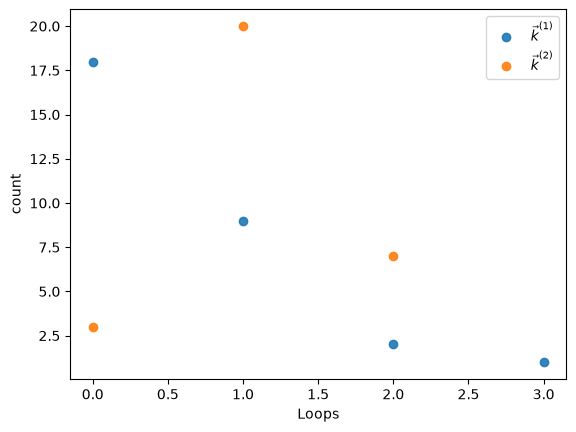

In [ ]:
#Call Link_Stub_Reconnection for the given degree distributions in Homework2. Add the code below.
seq1 = [2]*12
seq2 = [7,4,2] + [1]*9

results1 = {}
results2 = {}
for i in range(30):
    ei = Link_Stub_Reconnection(seq1)
    g1 = nx.Graph()
    g1.add_edges_from(ei)
    g1_self = nx.number_of_selfloops(g1)
    g1_parallel = sum(max(0, g1.number_of_edges(u, v) - 1) for u, v in g1.edges())
    results1[i] = (g1_self, g1_parallel)

    
    ei = Link_Stub_Reconnection(seq2)
    g2 = nx.Graph()
    g2.add_edges_from(ei)
    g2_self = nx.number_of_selfloops(g2)
    g2_parallel = sum(max(0, g2.number_of_edges(u, v) - 1) for u, v in g2.edges())
    results2[i] = (g2_self, g2_parallel)

fig, ax = plt.subplots(1, 1)
l1, p1 = [], []
for l, p in results1.values():
    l1.append(l)
    p1.append(p)
l2, p2 = [], []
for l, p in results2.values():
    l2.append(l)
    p2.append(p)

l1_c, l2_c = np.unique_counts(l1), np.unique_counts(l2)
ax.scatter(l1_c[0], l1_c[1], alpha=0.9, label=r"$\vec{k}^{(1)}$")
ax.scatter(l2_c[0], l2_c[1], alpha=0.9, label=r"$\vec{k}^{(2)}$")
ax.set_xlabel("Loops")    
ax.set_ylabel("count")
plt.legend()


### Discussion Results 7.2


From the figure above it is clearly visible that sequence $\vec{k}^{(2)}$ has a higher number of self loops than $\vec{k}^{(1)}$. This is easily explained by the fact that $\vec{k}^{(2)}$ has nodes with a higher degree (7,4, and 2), and then for the rest only nodes with a degree of 1. The vertices with only degree one are unable to create a self loop. However, the vertex with 7, or 4 stubs are likely to create self loops. The expected number of self loops for a vertex with $k_i$ stubs is given by $\mathbb{E}_{self}(k_i) = \frac{k_i\cdot (k_i-1)}{2(N-1)}$, where $N$ is the total number of stubs. This gives a expected number of self loops for a graph with the degree sequence $\vec{k}^{(2)}$ of $\mathbb{E}_{self}(7) + \mathbb{E}_{self}(4) + \mathbb{E}_{self}(2) = \frac{56}{2\cdot 21} = \frac{4}{3}$. For the degree sequence $\vec{k}^{(1)}$ this expectation value is given by $12 \cdot \mathbb{E}_{self}(2) = 12 \cdot \frac{2}{2 \cdot 23} = \frac{12}{23}$. This is clearly less than for $\vec{k}^{(2)}$ so it is expected that for sequence two we observe more self loops. 

In [27]:
def BA_sublinear_PA(N, m0, m):
  #write the code for BA_sublinear_PA model from homework 3.
  #Input: N= total number of nodes, m0= starting nodes, m= number of edges formed by each newly joined node
  adj = np.zeros((N, N))
  for i in range(m0 - 1):
    for j in range(i+1, m0):
      adj[i, j] = 1
      adj[j, i] = 1

  for new_node in range(m0, N):
    sqrt_degree = np.sqrt(np.sum(adj[:new_node, :new_node], axis=1))

    p = sqrt_degree / np.sum(sqrt_degree)
    selected_nodes = np.random.choice(range(new_node), size=m, p=p)

    for node in selected_nodes:
      adj[new_node, node] = 1
      adj[node, new_node] = 1

  return adj

In [28]:
def BA_superlinear_PA(N, m0, m):
  #write the code for BA_sublinear_PA model from homework 3.
  #Input: N= total number of nodes, m0= starting nodes, m= number of edges formed by each newly joined node
  adj = np.zeros((N, N))
  for i in range(m0 - 1):
    for j in range(i+1, m0):
      adj[i, j] = 1
      adj[j, i] = 1

  for new_node in range(m0, N):
    square_degree = np.sum(adj[:new_node, :new_node], axis=1)**2

    p = square_degree / np.sum(square_degree)
    selected_nodes = np.random.choice(range(new_node), size=m, p=p)

    for node in selected_nodes:
      adj[new_node, node] = 1
      adj[node, new_node] = 1

  return adj

In [29]:
#write the code to calculate the average degree, maximum degree, and degree variance for each network. (Homework 7.3)
G_sub = BA_sublinear_PA(N=1000, m0=5, m=3)
G_sup = BA_superlinear_PA(N=1000, m0=5, m=3)

deg_seq_sub = G_sub.sum(axis=1)
deg_seq_sup = G_sup.sum(axis=1)

avg_deg_sub, max_deg_sub, var_deg_sub = deg_seq_sub.mean(), deg_seq_sub.max(), deg_seq_sub.var()
print(f"""======== Sublinear =========\n Average degree: {avg_deg_sub} \n Max degree: {max_deg_sub}\n Variance degrees: {var_deg_sub}\n""")

avg_deg_sup, max_deg_sup, var_deg_sup = deg_seq_sup.mean(), deg_seq_sup.max(), deg_seq_sup.var()
print(f"""======== Superlinear =========\n Average degree: {avg_deg_sup}\n Max degree: {max_deg_sup}\n Variance degrees: {var_deg_sup}\n""")

======== Sublinear =========
 Average degree: 5.962 
 Max degree: 47.0
 Variance degrees: 19.348556000000002

======== Superlinear =========
 Average degree: 4.264
 Max degree: 880.0
 Variance degrees: 1204.1043039999997



[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


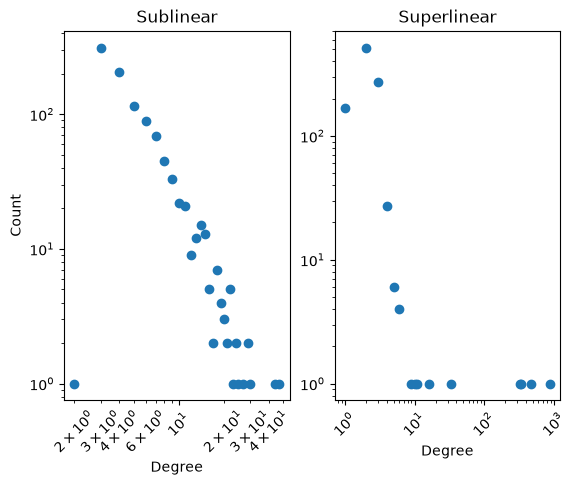

In [ ]:
#write the code to plot degree distribution of BA_sublinear_PA and BA_superlinear_PA functions using N of your choice. (Homework 7.3)
import matplotlib.ticker as ticker

fig, ax = plt.subplots(1, 2)

sub_dist = np.unique_counts(deg_seq_sub)
sup_dist = np.unique_counts(deg_seq_sup)
sub_order = np.argsort(sub_dist[0])
sup_order = np.argsort(sup_dist[0])

ax[0].scatter(sub_dist[0][sub_order], sub_dist[1][sub_order])
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel("Degree")
ax[0].set_ylabel("Count")
ax[0].set_title("Sublinear")
ax[0].tick_params(axis='x', rotation=45, which='both')
ax[0].xaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=5))

ax[1].scatter(sup_dist[0][sup_order], sup_dist[1][sup_order])
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_xlabel("Degree")
ax[1].set_title("Superlinear")
ax[1].tick_params(axis='x', rotation=45)
ax[1].xaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=5))

### Discussion Results 7.3

From the figure of the sublinear preferential attachment model it is seen that it follows a scale-free degree distribution since it almost follows a linear line on the log-log plot. The superlinear preferential attachment model seems to lose this property. It seems that almost all nodes have just a few connections with a couple of vertices which have a very high degree. In the superlinear preferential attachment model the probability of connecting to another vertex is determined by $P_i = \frac{k_i^2}{\sum_{j}k_j}$ which reinforces the "rich get richer" effect as the vertices with a low degree get completely overshadowed by the vertices with a high degree. However, with the sublinear preferential attachment model this effect actually gets decreased.  